Dataset created successfully!
Number of records: 100
Dataset saved successfully as student_exam_dataset.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Training records: 80
Testing records: 20
Model trained successfully!
Predictions completed!
MODEL EVALUATION
----------------
Mean Absolute Error (MAE): 3.66
Mean Squared Error (MSE): 19.3
R² Score: 0.92


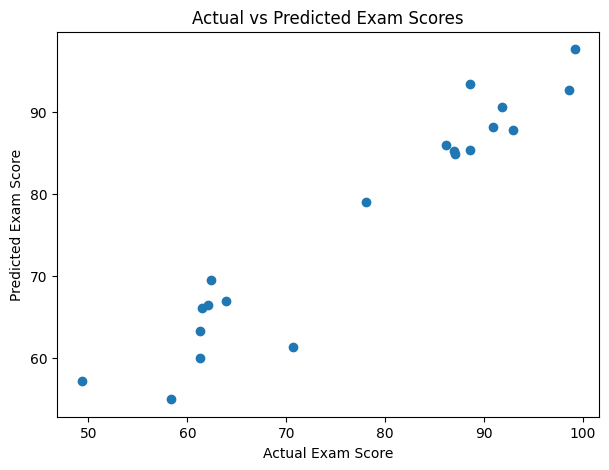

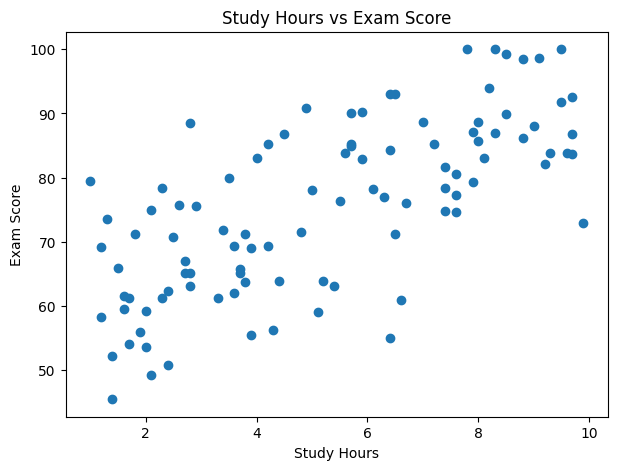

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cace5d3eea627eb51c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import gradio as gr

# Create a reproducible dataset
np.random.seed(42)

# Number of students
n = 100

# Input features
study_hours = np.random.uniform(1, 10, n)
attendance = np.random.uniform(50, 100, n)
previous_marks = np.random.uniform(40, 95, n)
assignments = np.random.randint(1, 11, n)

# Generate exam scores
exam_score = (
    3.5 * study_hours
    + 0.25 * attendance
    + 0.45 * previous_marks
    + 1.5 * assignments
    + np.random.normal(0, 4, n)
)

# Keep scores between 0 and 100
exam_score = np.clip(exam_score, 0, 100)

# Create DataFrame
df = pd.DataFrame({
    "Study_Hours": study_hours.round(1),
    "Attendance": attendance.round(1),
    "Previous_Marks": previous_marks.round(1),
    "Assignments_Completed": assignments,
    "Exam_Score": exam_score.round(1)
})

print("Dataset created successfully!")
print("Number of records:", len(df))
df.head(10)
# Save dataset
df.to_csv("student_exam_dataset.csv", index=False)

print("Dataset saved successfully as student_exam_dataset.csv")
from google.colab import files

files.download("student_exam_dataset.csv")
# Input features
X = df[
    [
        "Study_Hours",
        "Attendance",
        "Previous_Marks",
        "Assignments_Completed"
    ]
]

# Target variable
y = df["Exam_Score"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")
# Predict exam scores for test data
y_pred = model.predict(X_test)

print("Predictions completed!")
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("----------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("R² Score:", round(r2, 2))
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Exam Scores")

plt.show()
plt.figure(figsize=(7, 5))

plt.scatter(df["Study_Hours"], df["Exam_Score"])

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")

plt.show()
def predict_score(study_hours, attendance, previous_marks, assignments):

    # Create input data
    input_data = pd.DataFrame({
        "Study_Hours": [study_hours],
        "Attendance": [attendance],
        "Previous_Marks": [previous_marks],
        "Assignments_Completed": [assignments]
    })

    # Predict score
    prediction = model.predict(input_data)[0]

    # Keep prediction between 0 and 100
    prediction = np.clip(prediction, 0, 100)

    # Determine performance
    if prediction >= 75:
        performance = "Good Performance"
    elif prediction >= 50:
        performance = "Average Performance"
    else:
        performance = "Needs Improvement"

    return f"{prediction:.2f}%", performance
with gr.Blocks(title="Student Exam Score Prediction") as demo:

    gr.Markdown("""
        # 📚 Student Exam Score Prediction

        Predict a student's exam score using Machine Learning.
        """)

    gr.Markdown(
        """
        Enter the student's academic details below.
        """
    )

    with gr.Row():

        study_hours = gr.Slider(
            minimum=1,
            maximum=10,
            value=5,
            step=0.5,
            label="Study Hours per Day"
        )

        attendance = gr.Slider(
            minimum=50,
            maximum=100,
            value=75,
            step=1,
            label="Attendance (%)"
        )

    with gr.Row():

        previous_marks = gr.Slider(
            minimum=40,
            maximum=100,
            value=70,
            step=1,
            label="Previous Marks (%)"
        )

        assignments = gr.Slider(
            minimum=1,
            maximum=10,
            value=5,
            step=1,
            label="Assignments Completed"
        )

    predict_button = gr.Button("Predict Exam Score")

    predicted_score = gr.Textbox(
        label="Predicted Exam Score"
    )

    performance = gr.Textbox(
        label="Performance"
    )

    predict_button.click(
        fn=predict_score,
        inputs=[
            study_hours,
            attendance,
            previous_marks,
            assignments
        ],
        outputs=[
            predicted_score,
            performance
        ]
    )

demo.launch(share=True)